# MSCS-634 Lab 4: Regression Analysis with Regularization Techniques

**Mohammed Rehaan**  
**005046243**  
**MSCS-634-B01: Advanced Big Data and Data Mining**  
**University of the Cumberlands**  
**Dr. Penmatsa**

This lab uses scikit-learn's Diabetes dataset to compare simple linear regression, multiple regression, polynomial regression, Ridge regression, and Lasso regression. The goal is to measure how model complexity and regularization affect prediction of one-year disease progression.

## 1. Data preparation and exploration

The Diabetes dataset has 442 observations and ten baseline health measurements. The target is a quantitative measure of disease progression one year after baseline. The feature columns in this version of the dataset are mean-centered and scaled by scikit-learn. Missing values and duplicate rows are still checked rather than assumed away.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
TEST_SIZE = 0.20

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:.4f}".format)

In [2]:
diabetes = load_diabetes(as_frame=True)
X = diabetes.data.copy()
y = diabetes.target.copy()

print(f"Feature matrix shape: {X.shape}")
print(f"Target shape: {y.shape}")
print(f"Missing feature values: {X.isna().sum().sum()}")
print(f"Missing target values: {y.isna().sum()}")
print(f"Duplicate feature rows: {X.duplicated().sum()}")
display(X.head())
display(y.describe().to_frame(name="disease_progression"))

Feature matrix shape: (442, 10)
Target shape: (442,)
Missing feature values: 0
Missing target values: 0
Duplicate feature rows: 0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.0381,0.0507,0.0617,0.0219,-0.0442,-0.0348,-0.0434,-0.0026,0.0199,-0.0176
1,-0.0019,-0.0446,-0.0515,-0.0263,-0.0084,-0.0192,0.0744,-0.0395,-0.0683,-0.0922
2,0.0853,0.0507,0.0445,-0.0057,-0.0456,-0.0342,-0.0324,-0.0026,0.0029,-0.0259
3,-0.0891,-0.0446,-0.0116,-0.0367,0.0122,0.0250,-0.0360,0.0343,0.0227,-0.0094
4,0.0054,-0.0446,-0.0364,0.0219,0.0039,0.0156,0.0081,-0.0026,-0.0320,-0.0466


,disease_progression
count,442.0000
mean,152.1335
std,77.0930
min,25.0000
25%,87.0000
50%,140.5000
75%,211.5000
max,346.0000


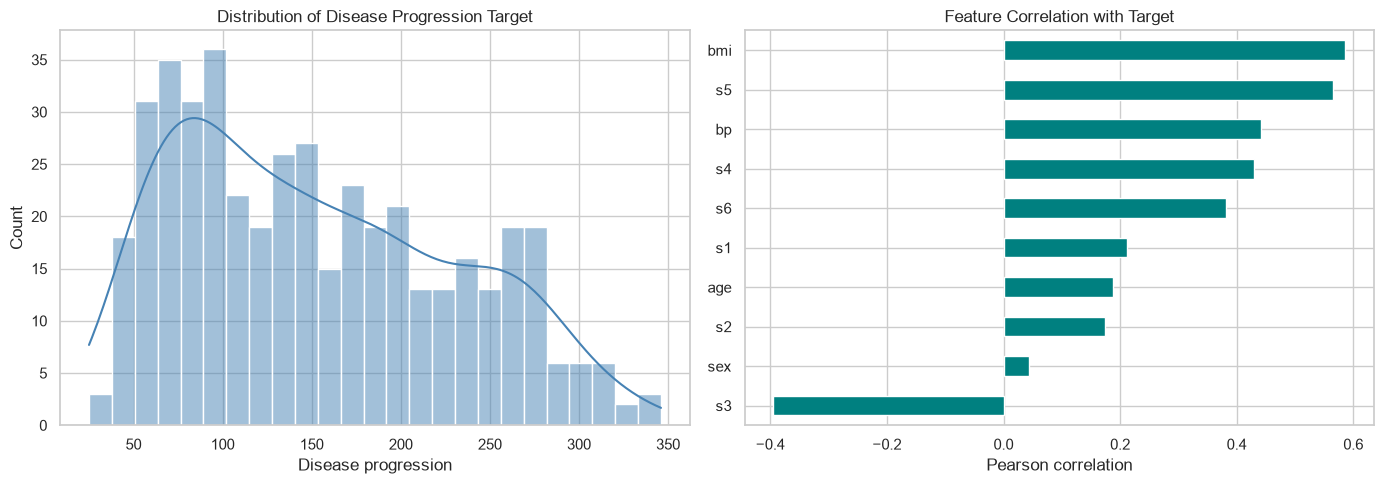

No rows were removed because the dataset contains no missing values or duplicate feature rows.


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(y, bins=25, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of Disease Progression Target")
axes[0].set_xlabel("Disease progression")

correlations = X.assign(target=y).corr(numeric_only=True)["target"].drop("target").sort_values()
correlations.plot(kind="barh", ax=axes[1], color="teal")
axes[1].set_title("Feature Correlation with Target")
axes[1].set_xlabel("Pearson correlation")

plt.tight_layout()
plt.show()

print("No rows were removed because the dataset contains no missing values or duplicate feature rows.")

### Train-test split and evaluation helper

All models use the same 80/20 split. Keeping the test set unchanged makes the comparisons fair. MAE and RMSE are measured in target units, while R-squared shows the share of variation explained on the held-out data.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

def evaluate_model(name, model, X_train, X_test, y_train, y_test):
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "MSE": mean_squared_error(y_test, predictions),
        "RMSE": mean_squared_error(y_test, predictions) ** 0.5,
        "R2": r2_score(y_test, predictions),
        "model": model,
        "predictions": predictions,
    }

def actual_vs_predicted_plot(y_actual, y_predicted, title):
    lower = min(y_actual.min(), y_predicted.min())
    upper = max(y_actual.max(), y_predicted.max())
    plt.figure(figsize=(7, 6))
    plt.scatter(y_actual, y_predicted, alpha=0.75, color="steelblue")
    plt.plot([lower, upper], [lower, upper], "r--", label="Perfect prediction")
    plt.xlabel("Actual disease progression")
    plt.ylabel("Predicted disease progression")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()

## 2. Simple linear regression

BMI is used as the single predictor because it has the strongest positive correlation with the target among the ten available features. This model is intentionally simple, so it provides a useful baseline before the remaining measurements are included.

,Model,MAE,MSE,RMSE,R2
0,Simple Linear Regression (BMI),52.2600,4061.8259,63.7325,0.2334


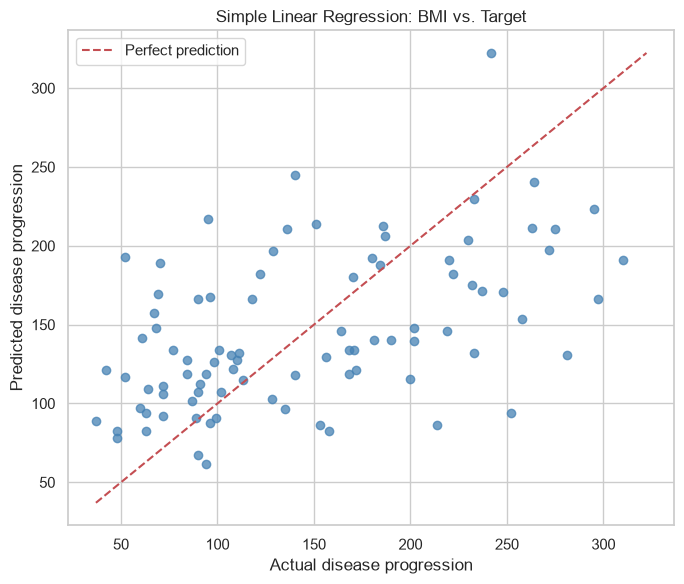

In [5]:
bmi_train = X_train[["bmi"]]
bmi_test = X_test[["bmi"]]

simple_result = evaluate_model(
    "Simple Linear Regression (BMI)",
    LinearRegression(),
    bmi_train,
    bmi_test,
    y_train,
    y_test,
)

display(pd.DataFrame([simple_result]).drop(columns=["model", "predictions"]).round(4))
actual_vs_predicted_plot(
    y_test, simple_result["predictions"], "Simple Linear Regression: BMI vs. Target"
)

## 3. Multiple linear regression

The multiple regression model uses all ten health measurements. It can capture separate linear relationships from age, sex, BMI, blood pressure, and the six serum measurements. It still assumes that the contribution from each feature is linear and additive.

,Model,MAE,MSE,RMSE,R2
0,Multiple Linear Regression,42.7941,2900.1936,53.8534,0.4526


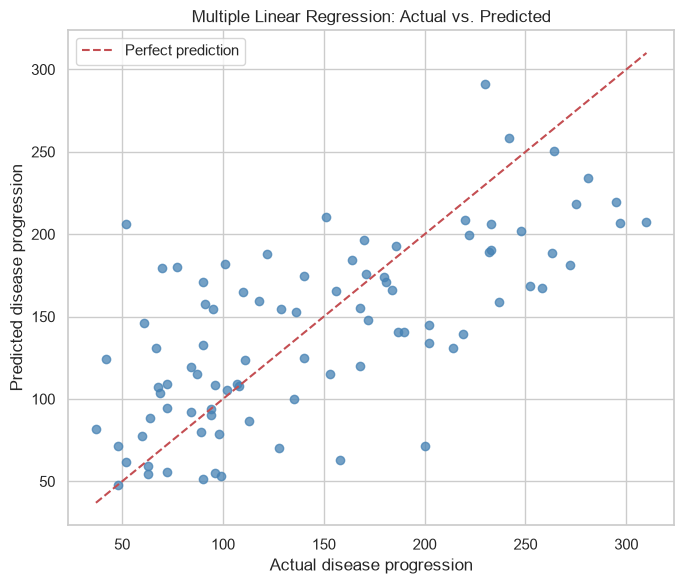

In [6]:
multiple_result = evaluate_model(
    "Multiple Linear Regression",
    LinearRegression(),
    X_train,
    X_test,
    y_train,
    y_test,
)

display(pd.DataFrame([multiple_result]).drop(columns=["model", "predictions"]).round(4))
actual_vs_predicted_plot(
    y_test, multiple_result["predictions"], "Multiple Linear Regression: Actual vs. Predicted"
)

## 4. Polynomial regression

Polynomial features add squared terms and feature interactions. Degrees 1, 2, 3, and 5 are tested. Degree 1 is the same functional form as multiple linear regression, while higher degrees can fit more complicated patterns. A higher training score without a matching test score is evidence that the extra flexibility is learning noise.

,Model,MAE,MSE,RMSE,R2,Train R2
0,Polynomial Regression (degree=1),42.7941,2900.1936,53.8534,0.4526,0.5279
1,Polynomial Regression (degree=2),43.5817,3096.0283,55.6420,0.4156,0.6062
2,Polynomial Regression (degree=3),161.1896,77808.8016,278.9423,-13.6860,0.8766
3,Polynomial Regression (degree=5),182.6029,68178.0844,261.1093,-11.8683,1.0000


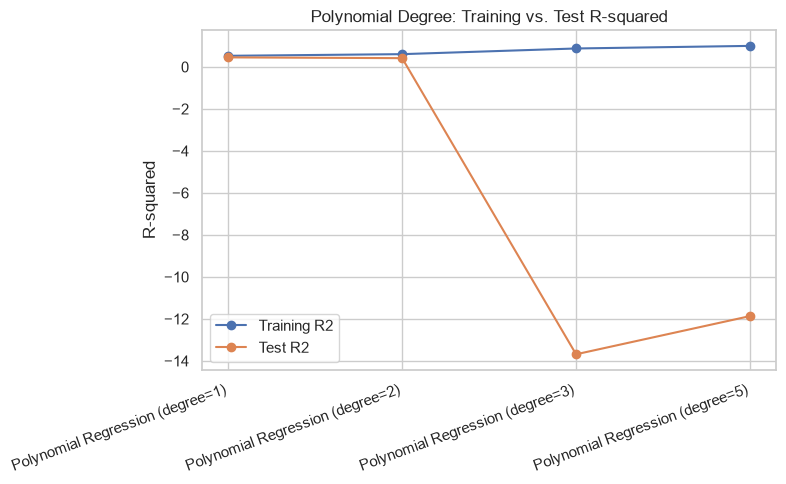

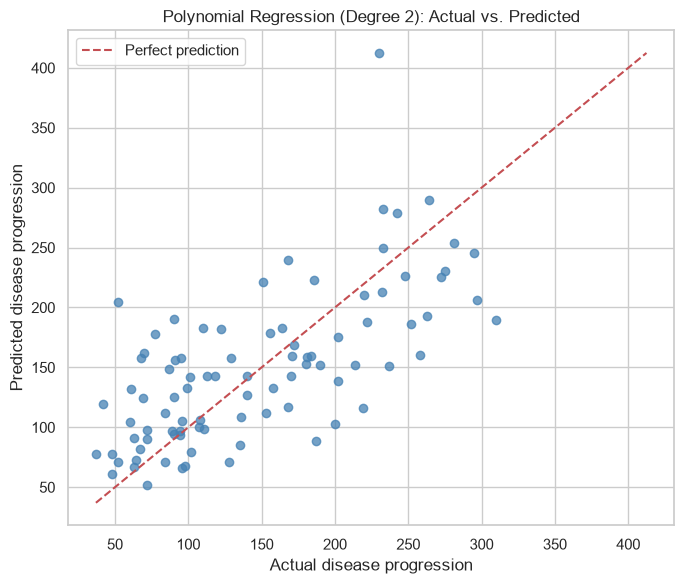

In [7]:
polynomial_results = []
polynomial_models = {}

for degree in [1, 2, 3, 5]:
    polynomial_model = Pipeline(
        [
            ("polynomial_features", PolynomialFeatures(degree=degree, include_bias=False)),
            ("scaler", StandardScaler()),
            ("linear_regression", LinearRegression()),
        ]
    )
    result = evaluate_model(
        f"Polynomial Regression (degree={degree})",
        polynomial_model,
        X_train,
        X_test,
        y_train,
        y_test,
    )
    result["Train R2"] = polynomial_model.score(X_train, y_train)
    polynomial_results.append(result)
    polynomial_models[degree] = result

polynomial_table = pd.DataFrame(polynomial_results).drop(columns=["model", "predictions"])
display(polynomial_table.round(4))

plt.figure(figsize=(8, 5))
plt.plot(polynomial_table["Model"], polynomial_table["Train R2"], marker="o", label="Training R2")
plt.plot(polynomial_table["Model"], polynomial_table["R2"], marker="o", label="Test R2")
plt.xticks(rotation=20, ha="right")
plt.ylabel("R-squared")
plt.title("Polynomial Degree: Training vs. Test R-squared")
plt.legend()
plt.tight_layout()
plt.show()

actual_vs_predicted_plot(
    y_test,
    polynomial_models[2]["predictions"],
    "Polynomial Regression (Degree 2): Actual vs. Predicted",
)

## 5. Ridge and Lasso regularization

Ridge and Lasso both penalize large coefficient values. Ridge uses an L2 penalty, which shrinks coefficients but normally keeps every feature. Lasso uses an L1 penalty, which can shrink some coefficients all the way to zero and act like feature selection. The alpha value controls penalty strength, and it is chosen with five-fold cross-validation on the training data only.

In [8]:
alpha_values = np.logspace(-4, 3, 20)

ridge_search = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("ridge", Ridge())]),
    param_grid={"ridge__alpha": alpha_values},
    scoring="neg_root_mean_squared_error",
    cv=5,
)
lasso_search = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("lasso", Lasso(max_iter=10000))]),
    param_grid={"lasso__alpha": alpha_values},
    scoring="neg_root_mean_squared_error",
    cv=5,
)

ridge_result = evaluate_model(
    "Ridge Regression",
    ridge_search,
    X_train,
    X_test,
    y_train,
    y_test,
)
lasso_result = evaluate_model(
    "Lasso Regression",
    lasso_search,
    X_train,
    X_test,
    y_train,
    y_test,
)

best_ridge_alpha = ridge_result["model"].best_params_["ridge__alpha"]
best_lasso_alpha = lasso_result["model"].best_params_["lasso__alpha"]
lasso_coefficients = lasso_result["model"].best_estimator_.named_steps["lasso"].coef_

regularization_table = pd.DataFrame([ridge_result, lasso_result]).drop(columns=["model", "predictions"])
display(regularization_table.round(4))
print(f"Best Ridge alpha from cross-validation: {best_ridge_alpha:.6f}")
print(f"Best Lasso alpha from cross-validation: {best_lasso_alpha:.6f}")
print(f"Lasso coefficients set to zero: {(np.isclose(lasso_coefficients, 0)).sum()} of {len(lasso_coefficients)}")

,Model,MAE,MSE,RMSE,R2
0,Ridge Regression,42.9592,2860.6739,53.4853,0.4601
1,Lasso Regression,42.7936,2817.6583,53.0816,0.4682


Best Ridge alpha from cross-validation: 33.598183
Best Lasso alpha from cross-validation: 1.128838
Lasso coefficients set to zero: 1 of 10


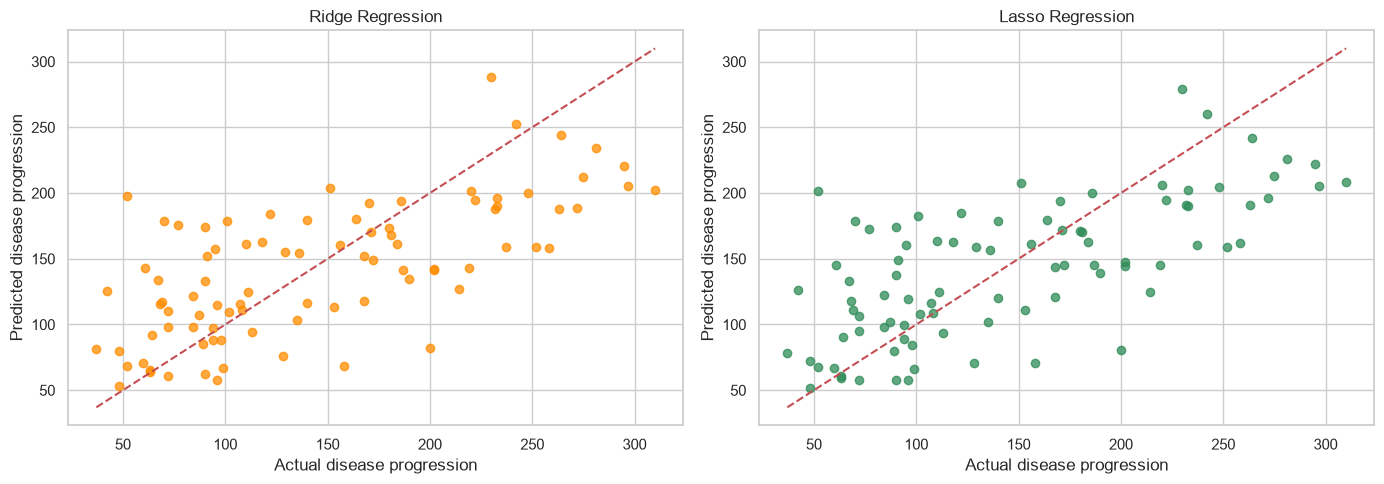

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, result, color in zip(
    axes, [ridge_result, lasso_result], ["darkorange", "seagreen"]
):
    actual = y_test
    predicted = result["predictions"]
    lower = min(actual.min(), predicted.min())
    upper = max(actual.max(), predicted.max())
    ax.scatter(actual, predicted, alpha=0.75, color=color)
    ax.plot([lower, upper], [lower, upper], "r--")
    ax.set_xlabel("Actual disease progression")
    ax.set_ylabel("Predicted disease progression")
    ax.set_title(result["Model"])

plt.tight_layout()
plt.show()

## 6. Model comparison and analysis

The table below compares every final model on the same held-out observations. Lower MAE, MSE, and RMSE are better. Higher R-squared is better. The polynomial results should be read with the training score beside the test score because a large gap is a direct warning that the model is overfitting.

,Model,MAE,MSE,RMSE,R2
0,Lasso Regression,42.7936,2817.6583,53.0816,0.4682
1,Ridge Regression,42.9592,2860.6739,53.4853,0.4601
2,Polynomial Regression (degree=1),42.7941,2900.1936,53.8534,0.4526
3,Multiple Linear Regression,42.7941,2900.1936,53.8534,0.4526
4,Polynomial Regression (degree=2),43.5817,3096.0283,55.6420,0.4156
5,Simple Linear Regression (BMI),52.2600,4061.8259,63.7325,0.2334
6,Polynomial Regression (degree=5),182.6029,68178.0844,261.1093,-11.8683
7,Polynomial Regression (degree=3),161.1896,77808.8016,278.9423,-13.6860


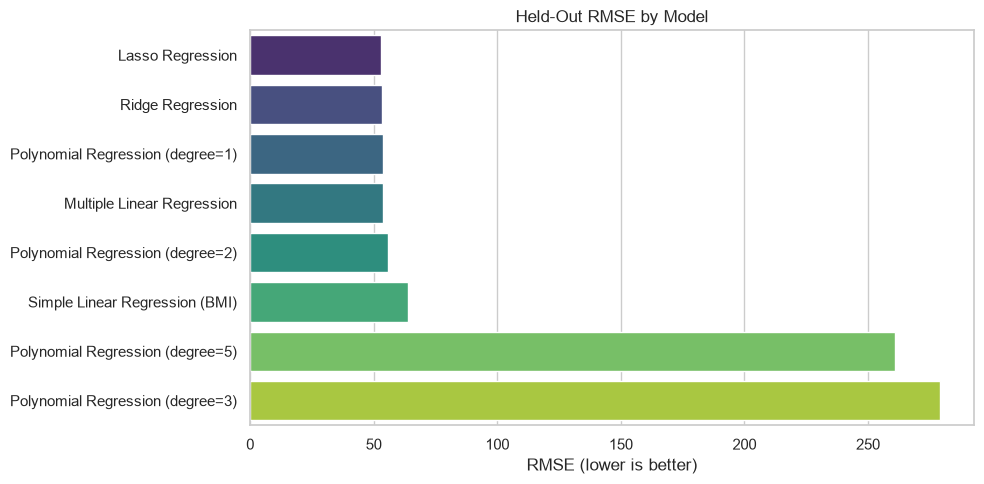

Best held-out model: Lasso Regression (RMSE=53.08, R2=0.468)


In [10]:
comparison_results = [
    simple_result,
    multiple_result,
    *polynomial_results,
    ridge_result,
    lasso_result,
]
comparison = (
    pd.DataFrame(comparison_results)
    .drop(columns=["model", "predictions", "Train R2"], errors="ignore")
    .sort_values("RMSE")
    .reset_index(drop=True)
)
display(comparison.round(4))

plt.figure(figsize=(10, 5))
sns.barplot(data=comparison, x="RMSE", y="Model", hue="Model", legend=False, palette="viridis")
plt.title("Held-Out RMSE by Model")
plt.xlabel("RMSE (lower is better)")
plt.ylabel("")
plt.tight_layout()
plt.show()

best_model = comparison.iloc[0]
print(
    f"Best held-out model: {best_model['Model']} "
    f"(RMSE={best_model['RMSE']:.2f}, R2={best_model['R2']:.3f})"
)

### Findings

Using all ten measurements improves on the one-feature BMI model because disease progression is related to more than BMI alone. The comparison table gives the exact held-out results for this split. Polynomial degree increases feature count quickly, and the training-versus-test chart shows whether that flexibility generalizes or begins fitting the training sample too closely.

Ridge and Lasso select their alpha values through cross-validation instead of choosing a penalty by guesswork. Ridge keeps correlated measurements in the model but reduces their coefficient size. Lasso can remove weak predictors when its alpha is large enough. This is useful when a simpler model is preferred, although the best test score remains the deciding factor.

The Diabetes dataset is fairly small, so very high polynomial degrees are not a good default. In practice, the regularized linear models are easier to explain and are less likely to become unstable when the feature set changes.